  infl        non-missing: 91.2%
  gdp_g       non-missing: 100.0%
  gov_claims  non-missing: 95.1%
  gov_cons    non-missing: 82.9%
  FAILED fiscal_bal (GC.BAL.CASH.GD.ZS): APIError: JSON decoding error (https://api.worldbank.org/v2/en/sources/2/series/GC.BAL.CASH.GD.ZS/country/BEN;BFA;CIV;GN
  fiscal_bal  non-missing:  0.0%
  m2_g        non-missing: 94.6%
  trade       non-missing: 84.0%
  oil_rents   non-missing: 94.9%
fiscal-variable coverage (share of country-years with inflation): {'gov_claims': np.float64(0.97), 'fiscal_bal': np.float64(0.0), 'gov_cons': np.float64(0.84)}
Fiscal variable used: gov_claims

Coverage by group (0 = non-CFA, 1 = CFA):
               y  gov_claims  gdp_g  trade  oil_rents
cfa_fixed                                           
0          0.89        0.93    1.0   0.78       0.94
1          0.96        0.98    1.0   0.96       0.96

Descriptives:
              y     fisc    gdp_g    trade  oil_rents
count  1490.00  1554.00  1634.00  1373.00    1550.00
me

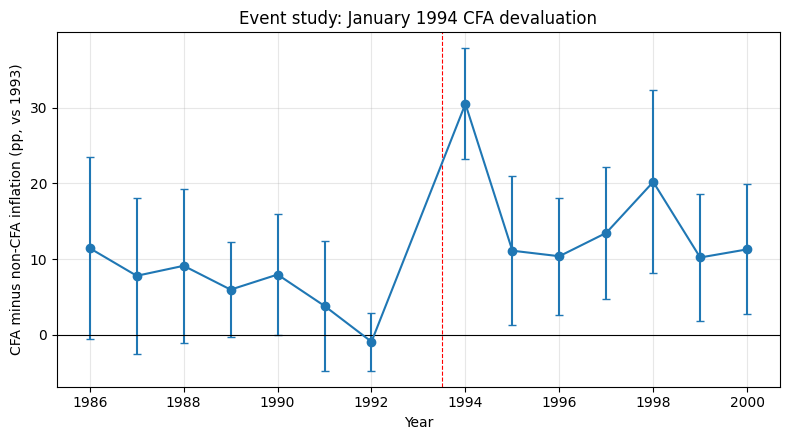

In [2]:
# %% [markdown]
# # CFA franc zone vs. non-CFA Africa: inflation, fiscal pressure and monetary-union design
# **Question.** Does the CFA franc zone's institutional design (peg + limits on central-bank lending)
# weaken the pass-through from fiscal pressure to inflation, and did the 1994 devaluation change inflation?
#
# **Why this is identified (unlike the first notebook).**
# * The CFA dummy is time-invariant, so it vanishes under country fixed effects. The estimable object is the
#   *interaction* `fiscal x CFA` (does fiscal pressure pass through differently?) - identified WITH country+year FE.
# * An event study around the January 1994 devaluation uses within-country variation.
# * Dynamics (inflation persistence) are handled with FE and an Anderson-Hsiao IV estimator.
# * Standard errors: clustered by country (>=30 clusters) and Driscoll-Kraay (cross-country dependence).

# %% 0. Setup
!pip install -q wbgapi linearmodels
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS
from linearmodels.iv import IV2SLS
warnings.filterwarnings("ignore")

USE_SYNTHETIC = False      # True ONLY to test the code offline. Never use for results.
START, END = 1985, 2022
FISCAL_VAR = "auto"        # or one of: gov_claims, fiscal_bal, gov_cons
MIN_OBS_PER_COUNTRY = 10

# %% 1. Countries and indicators
WAEMU = ["BEN", "BFA", "CIV", "GNB", "MLI", "NER", "SEN", "TGO"]
CEMAC = ["CMR", "CAF", "TCD", "COG", "GNQ", "GAB"]
CFA = WAEMU + CEMAC                       # Comoros excluded: separate franc zone
NON_CFA = ["DZA", "AGO", "BWA", "BDI", "COD", "EGY", "ETH", "GHA", "GIN", "KEN", "LSO", "LBR", "MDG",
           "MWI", "MRT", "MUS", "MAR", "MOZ", "NAM", "NGA", "RWA", "SLE", "ZAF", "TZA", "TUN", "UGA",
           "ZMB", "GMB", "CPV"]
COUNTRIES = CFA + NON_CFA
JOIN_YEAR = {"GNB": 1997}                 # Guinea-Bissau joined WAEMU in 1997 (others in before START)

INDICATORS = {
    "infl":       "FP.CPI.TOTL.ZG",       # CPI inflation, annual %
    "gdp_g":      "NY.GDP.MKTP.KD.ZG",    # real GDP growth
    "gov_claims": "FS.AST.CGOV.GD.ZS",    # bank claims on central government, % GDP  (fiscal-dominance proxy)
    "gov_cons":   "NE.CON.GOVT.ZS",       # government consumption, % GDP             (fiscal-pressure proxy)
    "fiscal_bal": "GC.BAL.CASH.GD.ZS",    # cash surplus/deficit, % GDP               (sparse)
    "m2_g":       "FM.LBL.BMNY.ZG",       # broad money growth (endogenous: robustness only)
    "trade":      "NE.TRD.GNFS.ZS",       # trade openness, % GDP
    "oil_rents":  "NY.GDP.PETR.RT.ZS",    # oil rents, % GDP
}

# %% 2. Data download (with retries; failures are reported, never silently replaced)
def fetch_indicator(code, name, countries, retries=3):
    import wbgapi as wb
    err = None
    for a in range(retries):
        try:
            df = wb.data.DataFrame(code, economy=countries, time=range(START, END + 1),
                                   numericTimeKeys=True, labels=False).reset_index()
            df = df.rename(columns={df.columns[0]: "country"}).melt(
                id_vars="country", var_name="year", value_name=name)
            df["year"] = pd.to_numeric(df["year"].astype(str).str.replace("YR", ""))
            return df
        except Exception as e:
            err = e
            time.sleep(2 * (a + 1))
    print(f"  FAILED {name} ({code}): {str(err)[:120]}")
    return None


def download_raw():
    grid = pd.MultiIndex.from_product([COUNTRIES, range(START, END + 1)], names=["country", "year"]).to_frame(index=False)
    raw = grid
    for name, code in INDICATORS.items():
        d = fetch_indicator(code, name, COUNTRIES)
        if d is None:
            raw[name] = np.nan
        else:
            raw = raw.merge(d, on=["country", "year"], how="left")
        print(f"  {name:11s} non-missing: {raw[name].notna().mean():5.1%}")
    return raw


# %% 3. Synthetic data with KNOWN truth (offline test of the estimators only)
TRUTH = dict(rho=0.45, beta_nonCFA=0.30, beta_CFA=0.12, devaluation_1994=20.0)

def make_synthetic(seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for c in COUNTRIES:
        cfa_c = c in CFA
        a = rng.normal(2, 2)
        fisc = 10 + rng.normal(0, 3)
        infl_prev = 5.0
        fprev = fisc
        for t in range(START, END + 1):
            f = 10 + 0.8 * (fprev - 10) + rng.normal(0, 2.5) + (fisc - 10) * 0.2
            member = cfa_c and t >= JOIN_YEAR.get(c, 0)
            beta = TRUTH["beta_CFA"] if member else TRUTH["beta_nonCFA"]
            shock = rng.standard_t(4) * 2.0
            dev = {1994: TRUTH["devaluation_1994"], 1995: TRUTH["devaluation_1994"] / 2}.get(t, 0) if cfa_c else 0
            lam = 1.5 * np.sin(t / 5.0)                       # common time effect
            infl = a + lam + TRUTH["rho"] * infl_prev + beta * (fprev - 10) + shock + dev
            rows.append(dict(country=c, year=t, infl=infl, gdp_g=rng.normal(4, 3),
                             gov_claims=f if (t >= 1990 and rng.random() > 0.15) else np.nan,
                             gov_cons=12 + rng.normal(0, 2), fiscal_bal=f - 20 if rng.random() > 0.7 else np.nan,
                             m2_g=infl + rng.normal(5, 5), trade=40 + rng.normal(0, 15),
                             oil_rents=abs(rng.normal(3, 3))))
            infl_prev, fprev = infl, f
    return pd.DataFrame(rows)


# %% 4. Build the analysis panel
def prepare(raw):
    d = raw.copy()
    d["cfa_fixed"] = d["country"].isin(CFA).astype(int)
    d["cfa"] = [int(c in CFA and y >= JOIN_YEAR.get(c, 0)) for c, y in zip(d["country"], d["year"])]
    d["waemu"] = (d["country"].isin(WAEMU) & (d["cfa"] == 1)).astype(int)
    d["cemac"] = (d["country"].isin(CEMAC) & (d["cfa"] == 1)).astype(int)
    # log-inflation transform and winsorisation: hyperinflation episodes otherwise dominate OLS
    y = 100 * np.log1p(d["infl"].clip(lower=-50) / 100)
    lo, hi = y.quantile([0.01, 0.99])
    d["y"] = y.clip(lo, hi)
    d["trade"] = np.log(d["trade"].where(d["trade" ] > 0))
    d = d.set_index(["country", "year"]).sort_index()
    g = d.groupby(level=0)
    d["y_l1"] = g["y"].shift(1)
    return d


def choose_fiscal(d):
    base = d["y"].notna()
    cov = {k: d.loc[base, k].notna().mean() for k in ["gov_claims", "fiscal_bal", "gov_cons"]}
    print("fiscal-variable coverage (share of country-years with inflation):",
          {k: round(v, 2) for k, v in cov.items()})
    if FISCAL_VAR != "auto":
        return FISCAL_VAR
    for k in ["gov_claims", "fiscal_bal", "gov_cons"]:
        if cov[k] >= 0.5:
            return k
    raise ValueError("No fiscal variable has >=50% coverage; relax the threshold or change sources "
                     "(e.g. IMF WEO fiscal balance).")


def add_fiscal(d, fv):
    d = d.copy()
    d["fisc"] = d[fv]
    d["fisc_l1"] = d.groupby(level=0)["fisc"].shift(1)       # lag: limits reverse causality
    d["fisc_x_cfa"] = d["fisc_l1"] * d["cfa"]
    d["fisc_x_waemu"] = d["fisc_l1"] * d["waemu"]
    d["fisc_x_cemac"] = d["fisc_l1"] * d["cemac"]
    return d


# %% 5. Estimators
CONTROLS = ["gdp_g", "trade", "oil_rents"]

def sample(d, cols, min_obs=MIN_OBS_PER_COUNTRY, years=None):
    x = d[cols].dropna()
    if years is not None:
        x = x[(x.index.get_level_values(1) >= years[0]) & (x.index.get_level_values(1) <= years[1])]
    n = x.groupby(level=0).size()
    return x[x.index.get_level_values(0).isin(n[n >= min_obs].index)]


def fit_panel(d, xs, entity=True, time_fe=True, dk=False, years=None):
    x = sample(d, ["y"] + xs, years=years)
    mod = PanelOLS(x["y"], x[xs], entity_effects=entity, time_effects=time_fe, drop_absorbed=True)
    res = mod.fit(cov_type="kernel") if dk else mod.fit(cov_type="clustered", cluster_entity=True)
    return res, x


def anderson_hsiao(d, xs, drop_years=()):
    """First-difference IV: dy_t = rho*dy_{t-1} + b*dx_t + year dummies, instrument dy_{t-1} with y_{t-2}.
    Removes the Nickell bias of FE with lagged dependent variable. Lags built on the FULL grid."""
    g = d.groupby(level=0)
    dd = pd.DataFrame(index=d.index)
    dd["dy"] = g["y"].diff()
    dd["dy_l1"] = g["y"].shift(1) - g["y"].shift(2)
    dd["z"] = g["y"].shift(2)
    for xk in xs:
        dd["d_" + xk] = g[xk].diff()
    dd = dd.dropna()
    dd = dd[~dd.index.get_level_values(1).isin(list(drop_years))]
    n = dd.groupby(level=0).size()
    dd = dd[dd.index.get_level_values(0).isin(n[n >= MIN_OBS_PER_COUNTRY].index)]
    yr = pd.get_dummies(dd.index.get_level_values(1), prefix="yr", drop_first=True).astype(float)
    yr.index = dd.index
    exog = pd.concat([dd[["d_" + k for k in xs]], yr], axis=1)
    exog.insert(0, "const", 1.0)
    cl = pd.factorize(dd.index.get_level_values(0))[0]
    res = IV2SLS(dd["dy"], exog, dd[["dy_l1"]], dd[["z"]]).fit(cov_type="clustered", clusters=cl)
    return res, dd


def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""


def cell(res, k):
    if k not in res.params.index:
        return ""
    return f"{res.params[k]:.3f}{stars(res.pvalues[k])} ({res.std_errors[k]:.3f})"


def run_all(d):
    rows, store = {}, {}
    b = ["fisc_l1", "fisc_x_cfa"] + CONTROLS
    specs = {
        "(1) Pooled, year FE":           dict(xs=["cfa"] + b, entity=False),
        "(2) Country+year FE":           dict(xs=b),
        "(3) FE + lagged inflation":     dict(xs=["y_l1"] + b),
        "(4) FE, Driscoll-Kraay SE":     dict(xs=b, dk=True),
        "(5) FE, excl. 2020-22":         dict(xs=b, years=(START, 2019)),
        "(6) FE + M2 growth (endog.)":   dict(xs=b + ["m2_g"]),
        "(7) WAEMU vs CEMAC":            dict(xs=["fisc_l1", "fisc_x_waemu", "fisc_x_cemac"] + CONTROLS),
    }
    for name, kw in specs.items():
        res, x = fit_panel(d, **kw)
        store[name] = res
        rows[name] = {k: cell(res, k) for k in ["cfa", "fisc_l1", "fisc_x_cfa", "fisc_x_waemu", "fisc_x_cemac", "y_l1"]}
        rows[name]["N"] = int(res.nobs)
        rows[name]["countries"] = x.index.get_level_values(0).nunique()
    res, dd = anderson_hsiao(d, b)
    store["(8) Anderson-Hsiao IV"] = res
    rows["(8) Anderson-Hsiao IV"] = {"fisc_l1": cell(res, "d_fisc_l1"), "fisc_x_cfa": cell(res, "d_fisc_x_cfa"),
                                     "y_l1": cell(res, "dy_l1"), "N": int(res.nobs),
                                     "countries": dd.index.get_level_values(0).nunique()}
    # devaluation shock (1994-95) is a large common CFA shock that violates the AH instrument in 1994-97:
    res, dd = anderson_hsiao(d, b, drop_years=range(1994, 1998))
    store["(9) Anderson-Hsiao, excl. 1994-97"] = res
    rows["(9) Anderson-Hsiao, excl. 1994-97"] = {"fisc_l1": cell(res, "d_fisc_l1"), "fisc_x_cfa": cell(res, "d_fisc_x_cfa"),
                                                 "y_l1": cell(res, "dy_l1"), "N": int(res.nobs),
                                                 "countries": dd.index.get_level_values(0).nunique()}
    table = pd.DataFrame(rows).T.fillna("")
    return table, store


# %% 6. Event study around the 1994 CFA devaluation
def event_study(d, year0=1994, pre=8, post=6, drop=("GNB",)):
    x = d.reset_index()
    x = x[~x["country"].isin(drop) & x["year"].between(year0 - pre, year0 + post)][["country", "year", "y", "cfa_fixed"]]
    x = x.dropna()
    n = x.groupby("country").size()
    x = x[x["country"].isin(n[n >= pre + post - 4].index)]
    ks = [k for k in range(-pre, post + 1) if k != -1]
    for k in ks:
        x[f"k{k}"] = (x["cfa_fixed"] * (x["year"] == year0 + k)).astype(float)
    x = x.set_index(["country", "year"])
    cols = [f"k{k}" for k in ks]
    res = PanelOLS(x["y"], x[cols], entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
    est = pd.DataFrame({"k": ks, "coef": [res.params[c] for c in cols], "se": [res.std_errors[c] for c in cols]})
    est["lo"], est["hi"] = est["coef" ] - 1.96 * est["se"], est["coef" ] + 1.96 * est["se"]
    pre_idx = [i for i, k in enumerate(ks) if k < -1]
    R = np.zeros((len(pre_idx), len(cols)))
    for r, i in enumerate(pre_idx):
        R[r, i] = 1
    wt = res.wald_test(R, np.zeros(len(pre_idx)))
    return est, wt, x.index.get_level_values(0).nunique()


def plot_event(est, year0=1994):
    plt.figure(figsize=(8, 4.5))
    plt.errorbar(est["k"] + year0, est["coef"], yerr=1.96 * est["se"], fmt="o-", capsize=3)
    plt.axhline(0, color="k", lw=.8)
    plt.axvline(year0 - 0.5, color="r", ls="--", lw=.8)
    plt.xlabel("Year"); plt.ylabel("CFA minus non-CFA inflation (pp, vs 1993)")
    plt.title("Event study: January 1994 CFA devaluation")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()


# %% 7. Run
if USE_SYNTHETIC:
    print("*** SYNTHETIC DATA - pipeline test only; truth:", TRUTH, "***")
    raw = make_synthetic()
else:
    print("Downloading World Bank data ...")
    raw = download_raw()

P = prepare(raw)
fv = choose_fiscal(P)
print("Fiscal variable used:", fv)
P = add_fiscal(P, fv)

cov = P.groupby("cfa_fixed")[["y", fv, "gdp_g", "trade", "oil_rents"]].agg(lambda s: s.notna().mean()).round(2)
print("\nCoverage by group (0 = non-CFA, 1 = CFA):\n", cov)
print("\nDescriptives:\n", P[["y", "fisc", "gdp_g", "trade", "oil_rents"]].describe().round(2))

table, store = run_all(P)
print("\nRESULTS  (dep. var: log-inflation, winsorised; clustered-by-country SE in parentheses)")
print(table.to_string())
table.to_csv("cfa_results.csv")

est, wt, nc = event_study(P)
print(f"\nEvent study ({nc} countries). Joint test of pre-trends (k <= -2 all zero):\n", wt)
print(est.round(2).to_string(index=False))
plot_event(est)
est.to_csv("cfa_event_study.csv", index=False)


================ ROBUSTNESS ================

(a) Stability across data cleaning (A raw / B winsorised / C trimmed):
                            FE+lag: fisc FE+lag: fisc x CFA     DK: fisc x CFA AH(excl 94-97): fisc x CFA            AH rho     N countries
A raw                    0.073** (0.033)    -0.110* (0.063)  -0.110*** (0.038)             -0.158 (0.162)  0.866*** (0.160)  1146        38
B winsorised            0.094*** (0.033)    -0.123* (0.063)  -0.123*** (0.039)             -0.232 (0.174)  0.866*** (0.160)  1146        38
C winsorised + trimmed  0.122*** (0.042)     -0.096 (0.070)   -0.096** (0.044)            -0.215* (0.112)  0.348*** (0.064)  1095        38

(b) Leave-one-country-out, spec (3) on cleaned sample C:
  interaction range when dropping one country: [-0.151, -0.072]; significant (p<.10) in 1 of 43 runs
  most influential drops:
 dropped   coef     p
    CAF -0.151 0.004
    DZA -0.127 0.108
    BWA -0.112 0.118
    GNQ -0.079 0.280
    ZMB -0.073 0.263
    COG -0

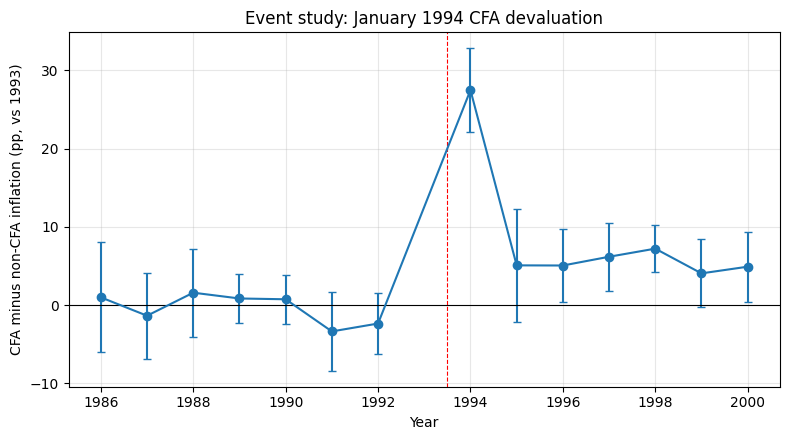


(d) Placebo: fake devaluation in 1990 (window 1985-1993, true 1994 shock excluded):
  Placebo coefficients should all be statistically indistinguishable from zero (CIs cover 0):
 k  coef   se    lo    hi
-5  6.12 2.38  1.46 10.78
-4  0.21 3.47 -6.59  7.00
-3 -2.14 2.88 -7.79  3.51
-2  0.80 3.04 -5.16  6.77
 0 -0.10 1.32 -2.69  2.49
 1 -4.21 2.73 -9.55  1.13
 2 -3.20 2.51 -8.13  1.73
 3 -0.86 1.66 -4.10  2.39


In [3]:
# 8. ROBUSTNESS: outliers, leave-one-country-out, cleaner event study, placebo
# Run AFTER section 7 (uses P, fv, run_all, event_study, plot_event defined above).

def clean_versions(P, fv, p=(0.01, 0.99)):
    """A = raw; B = winsorised regressors; C = B + drop hyperinflation / collapse country-years."""
    A = P
    B = P.copy()
    for c in [fv, "gdp_g", "oil_rents", "m2_g"]:
        lo, hi = B[c].quantile(p)
        B[c] = B[c].clip(lo, hi)
    B = add_fiscal(B, fv)
    C = B.copy()
    bad = (C["infl"] > 50) | (C["gdp_g"].abs() > 15) | (C["infl"] < -10)
    C.loc[bad, ["y", "fisc"]] = np.nan                      # treat as missing, not as data
    C["y_l1"] = C.groupby(level=0)["y"].shift(1)
    C = add_fiscal(C.assign(**{fv: C["fisc"]}), fv)
    return {"A raw": A, "B winsorised": B, "C winsorised + trimmed": C}


def stability_table(versions):
    rows = {}
    b = ["fisc_l1", "fisc_x_cfa"] + CONTROLS
    for vname, d in versions.items():
        r3, x3 = fit_panel(d, ["y_l1"] + b)
        r4, x4 = fit_panel(d, ["y_l1"] + b, dk=True)
        r9, d9 = anderson_hsiao(d, b, drop_years=range(1994, 1998))
        rows[vname] = {"FE+lag: fisc": cell(r3, "fisc_l1"), "FE+lag: fisc x CFA": cell(r3, "fisc_x_cfa"),
                       "DK: fisc x CFA": cell(r4, "fisc_x_cfa"),
                       "AH(excl 94-97): fisc x CFA": cell(r9, "d_fisc_x_cfa"), "AH rho": cell(r9, "dy_l1"),
                       "N": int(r3.nobs), "countries": x3.index.get_level_values(0).nunique()}
    return pd.DataFrame(rows).T


def leave_one_out(d, spec_xs=None):
    """Re-estimate the interaction dropping each country in turn. A result that hinges on one country is not a result."""
    b = ["y_l1", "fisc_l1", "fisc_x_cfa"] + CONTROLS if spec_xs is None else spec_xs
    out = []
    for c in sorted(d.index.get_level_values(0).unique()):
        dd = d[d.index.get_level_values(0) != c]
        try:
            r, _ = fit_panel(dd, b)
            out.append((c, r.params["fisc_x_cfa"], r.pvalues["fisc_x_cfa"]))
        except Exception:
            pass
    o = pd.DataFrame(out, columns=["dropped", "coef", "p"]).sort_values("coef")
    print(f"  interaction range when dropping one country: [{o.coef.min():.3f}, {o.coef.max():.3f}]; "
          f"significant (p<.10) in {(o.p < .10).sum()} of {len(o)} runs")
    print("  most influential drops:\n", pd.concat([o.head(3), o.tail(3)]).round(3).to_string(index=False))
    return o


def matched_controls(P, max_pre_infl=25.0, max_any_infl=100.0, window=(1990, 1993)):
    """Non-CFA countries that look like CFA countries before 1994 (low inflation, no hyperinflation)."""
    inf = P["infl"].unstack(level=1)
    pre = inf.loc[:, window[0]:window[1]].mean(axis=1)
    mx = inf.loc[:, 1985:2000].max(axis=1)
    non = [c for c in NON_CFA if c in pre.index]
    keep = [c for c in non if pre[c] < max_pre_infl and mx[c] < max_any_infl]
    drop = [c for c in non if c not in keep]
    print(f"  matched non-CFA controls kept ({len(keep)}): {keep}\n  dropped ({len(drop)}): {drop}")
    return drop


print("\n================ ROBUSTNESS ================")
versions = clean_versions(P, fv)
print("\n(a) Stability across data cleaning (A raw / B winsorised / C trimmed):")
print(stability_table(versions).to_string())

print("\n(b) Leave-one-country-out, spec (3) on cleaned sample C:")
loo = leave_one_out(versions["C winsorised + trimmed"])

print("\n(c) Event study with matched controls:")
drop_nc = matched_controls(P)
est2, wt2, nc2 = event_study(P, drop=("GNB", *drop_nc))
print(f"  {nc2} countries. Pre-trend joint test p-value: {float(wt2.pval):.3f}")
print(est2.round(2).to_string(index=False))
plot_event(est2)

print("\n(d) Placebo: fake devaluation in 1990 (window 1985-1993, true 1994 shock excluded):")
estp, wtp, ncp = event_study(P, year0=1990, pre=5, post=3, drop=("GNB", *drop_nc))
print("  Placebo coefficients should all be statistically indistinguishable from zero (CIs cover 0):")
print(estp.round(2).to_string(index=False))

infl        : 91.2% non-missing
gdp_g       : 100.0% non-missing
gov_claims  : 95.1% non-missing
gov_debt    : 13.5% non-missing
FAILED gov_expense (GC.XPN.TOTL.GD.ZS): APIError: [502] Bad Gateway (https://api.worldbank.org/v2/en/sources/2/series/GC.XPN.TOTL.GD.ZS/country/BEN;BFA;CIV;GNB;MLI;NER;SEN;TGO/time/YR1985;YR1986;YR1987;YR1988;YR1989;YR19
gov_expense : 0.0% non-missing
FAILED gov_cons (NE.CON.GOVT.ZS): APIError: [502] Bad Gateway (https://api.worldbank.org/v2/en/sources/2/series/NE.CON.GOVT.ZS/country/BEN;BFA;CIV;GNB;MLI;NER;SEN;TGO/time/YR1985;YR1986;YR1987;YR1988;YR1989;YR1990;
gov_cons    : 0.0% non-missing
FAILED fiscal_bal (GC.BAL.CASH.GD.ZS): APIError: JSON decoding error (https://api.worldbank.org/v2/en/sources/2/series/GC.BAL.CASH.GD.ZS/country/BEN;BFA;CIV;GNB;MLI;NER;SEN;TGO/time/YR1985;YR1986;YR1987;YR1988;YR1989;YR
fiscal_bal  : 0.0% non-missing
m2_g        : 94.6% non-missing
trade       : 84.0% non-missing
oil_rents   : 94.9% non-missing

Fiscal proxy coverage:
 g

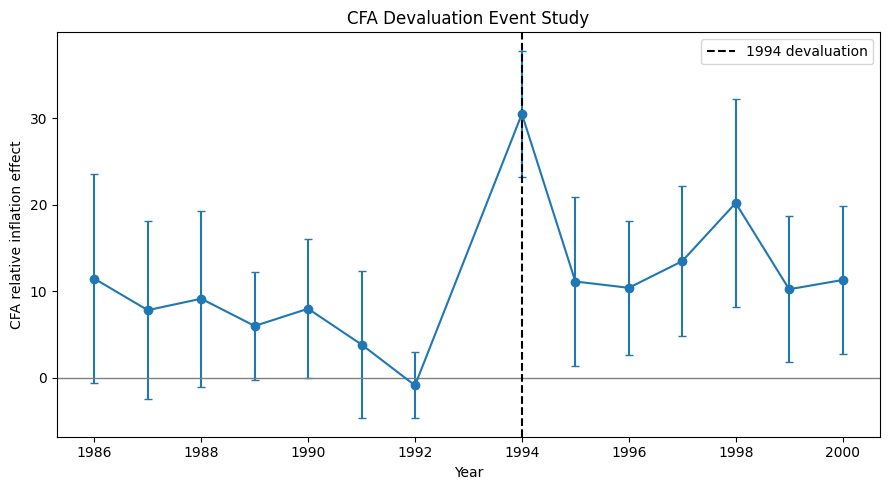

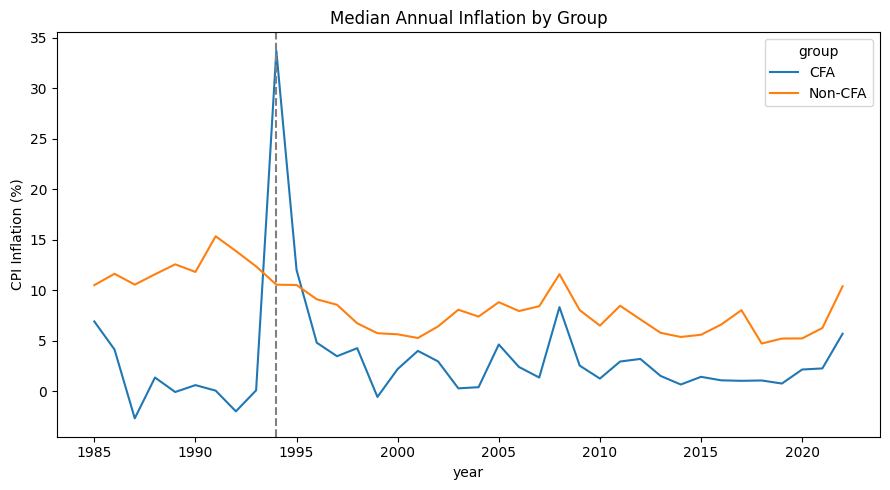


Results saved in: /content/Q3_CFA_outputs

IMPORTANT: These are observational associations, not automatically causal effects.


In [10]:

# ============================================================
# Q3: CFA FRANC ZONE VS NON-CFA AFRICA
# Inflation, Fiscal Pressure and Monetary Union Design
# Period: 1985–2022
# ============================================================

!pip install -q wbgapi linearmodels scipy matplotlib pandas numpy

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wbgapi as wb

from scipy.stats import norm
from linearmodels.panel import PanelOLS
from linearmodels.iv import IV2SLS

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. SETTINGS
# ============================================================

START, END = 1985, 2022

FISCAL_VAR = "gov_claims"
# Alternatives: gov_expense, gov_cons, gov_debt

MIN_OBS_PER_COUNTRY = 10

OUT = Path("Q3_CFA_outputs")
OUT.mkdir(exist_ok=True)

WAEMU = [
    "BEN", "BFA", "CIV", "GNB",
    "MLI", "NER", "SEN", "TGO"
]

CEMAC = [
    "CMR", "CAF", "TCD",
    "COG", "GNQ", "GAB"
]

CFA = WAEMU + CEMAC

NON_CFA = [
    "DZA", "AGO", "BWA", "BDI", "COD",
    "EGY", "ETH", "GHA", "GIN", "KEN",
    "LSO", "LBR", "MDG", "MWI", "MRT",
    "MUS", "MAR", "MOZ", "NAM", "NGA",
    "RWA", "SLE", "ZAF", "TZA", "TUN",
    "UGA", "ZMB", "GMB", "CPV"
]

COUNTRIES = CFA + NON_CFA

JOIN_YEAR = {"GNB": 1997}

INDICATORS = {
    "infl": "FP.CPI.TOTL.ZG",
    "gdp_g": "NY.GDP.MKTP.KD.ZG",
    "gov_claims": "FS.AST.CGOV.GD.ZS",
    "gov_debt": "GC.DOD.TOTL.GD.ZS",
    "gov_expense": "GC.XPN.TOTL.GD.ZS",
    "gov_cons": "NE.CON.GOVT.ZS",
    "fiscal_bal": "GC.BAL.CASH.GD.ZS",
    "m2_g": "FM.LBL.BMNY.ZG",
    "trade": "NE.TRD.GNFS.ZS",
    "oil_rents": "NY.GDP.PETR.RT.ZS"
}

CONTROLS = ["gdp_g", "trade", "oil_rents"]

# ============================================================
# 2. DOWNLOAD WORLD BANK DATA
# ============================================================

def fetch_indicator(code, name, retries=3):

    for attempt in range(retries):
        try:
            frames = []

            for j in range(0, len(COUNTRIES), 8):

                subset = COUNTRIES[j:j+8]

                z = wb.data.DataFrame(
                    code,
                    economy=subset,
                    time=range(START, END+1),
                    numericTimeKeys=True,
                    labels=False
                )

                z.index.name = "country"
                z = z.reset_index()

                z = z.rename(
                    columns={z.columns[0]: "country"}
                )

                z = z.melt(
                    id_vars="country",
                    var_name="year",
                    value_name=name
                )

                z["year"] = pd.to_numeric(
                    z["year"].astype(str).str.replace(
                        "YR", "", regex=False
                    ),
                    errors="coerce"
                )

                z[name] = pd.to_numeric(
                    z[name], errors="coerce"
                )

                frames.append(
                    z[["country", "year", name]]
                )

            return pd.concat(
                frames, ignore_index=True
            ).drop_duplicates(["country", "year"])

        except Exception as exc:

            if attempt == retries-1:
                print(
                    f"FAILED {name} ({code}): "
                    f"{str(exc)[:180]}"
                )
                return None

            time.sleep(2*(attempt+1))


def download_raw():

    d = pd.MultiIndex.from_product(
        [COUNTRIES, range(START, END+1)],
        names=["country", "year"]
    ).to_frame(index=False)

    for name, code in INDICATORS.items():

        z = fetch_indicator(code, name)

        if z is None:
            d[name] = np.nan
        else:
            d = d.merge(
                z,
                on=["country", "year"],
                how="left",
                validate="one_to_one"
            )

        print(
            f"{name:12s}: "
            f"{d[name].notna().mean():.1%} non-missing"
        )

    d.to_csv(
        OUT / "world_bank_raw.csv",
        index=False
    )

    return d

# ============================================================
# 3. PREPARE PANEL DATA
# ============================================================

def prepare(raw):

    d = raw.copy().sort_values(
        ["country", "year"]
    )

    d["cfa_fixed"] = (
        d["country"].isin(CFA).astype(int)
    )

    d["cfa"] = [
        int(c in CFA and y >= JOIN_YEAR.get(c, 0))
        for c, y in zip(d.country, d.year)
    ]

    d["waemu"] = (
        d.country.isin(WAEMU) &
        d.cfa.eq(1)
    ).astype(int)

    d["cemac"] = (
        d.country.isin(CEMAC) &
        d.cfa.eq(1)
    ).astype(int)

    inflation = pd.to_numeric(
        d["infl"], errors="coerce"
    )

    # Log transformation
    y = 100 * np.log1p(
        inflation.where(inflation > -100) / 100
    )

    # Winsorization
    lo, hi = y.quantile([0.01, 0.99])

    d["y"] = y.clip(lo, hi)

    # Log trade openness
    d["trade"] = np.log(
        d["trade"].where(d["trade"] > 0)
    )

    d = d.set_index(
        ["country", "year"]
    ).sort_index()

    d["y_l1"] = (
        d.groupby(level="country")["y"].shift(1)
    )

    return d

# ============================================================
# 4. FISCAL VARIABLES AND INTERACTIONS
# ============================================================

def add_fiscal(d, fiscal_variable):

    if fiscal_variable not in d.columns:
        raise ValueError(
            f"Missing fiscal variable: {fiscal_variable}"
        )

    d = d.copy()

    d["fisc"] = d[fiscal_variable]

    d["fisc_l1"] = (
        d.groupby(level="country")["fisc"].shift(1)
    )

    d["fisc_x_cfa"] = (
        d["fisc_l1"] * d["cfa"]
    )

    d["fisc_x_waemu"] = (
        d["fisc_l1"] * d["waemu"]
    )

    d["fisc_x_cemac"] = (
        d["fisc_l1"] * d["cemac"]
    )

    return d

# ============================================================
# 5. SAMPLE SELECTION
# ============================================================

def sample(
    d,
    cols,
    years=None,
    min_obs=MIN_OBS_PER_COUNTRY
):

    cols = list(cols)

    x = (
        d.loc[:, cols]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if years is not None:

        yr = x.index.get_level_values("year")

        x = x[
            (yr >= years[0]) &
            (yr <= years[1])
        ]

    n = x.groupby(level="country").size()

    x = x[
        x.index.get_level_values("country").isin(
            n[n >= min_obs].index
        )
    ]

    if x.empty:
        raise ValueError(
            f"No observations after filtering: {cols}"
        )

    return x

# ============================================================
# 6. PANEL REGRESSION
# ============================================================

def fit_panel(
    d,
    xs,
    entity=True,
    time_fe=True,
    dk=False,
    years=None
):

    if not isinstance(xs, (list, tuple)):
        raise TypeError(
            "xs must be a list of variable names, not a dict"
        )

    xs = list(xs)

    x = sample(
        d,
        ["y"] + xs,
        years=years
    )

    mod = PanelOLS(
        x["y"],
        x[xs],
        entity_effects=entity,
        time_effects=time_fe,
        drop_absorbed=True,
        check_rank=True
    )

    if dk:
        res = mod.fit(
            cov_type="kernel",
            kernel="bartlett",
            bandwidth=3
        )
    else:
        res = mod.fit(
            cov_type="clustered",
            cluster_entity=True
        )

    return res, x

# ============================================================
# 7. REGRESSION TABLE HELPERS
# ============================================================

def stars(p):

    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    else:
        return ""


def cell(res, name):

    if name not in res.params.index:
        return ""

    return (
        f"{res.params[name]:.3f}"
        f"{stars(res.pvalues[name])} "
        f"({res.std_errors[name]:.3f})"
    )


def slope_test(
    res,
    a="fisc_l1",
    b="fisc_x_cfa"
):

    if not {a, b}.issubset(res.params.index):
        return np.nan, np.nan, np.nan

    estimate = float(
        res.params[a] + res.params[b]
    )

    covariance = (
        res.cov.loc[[a, b], [a, b]].to_numpy()
    )

    se = float(
        np.sqrt(max(0, covariance.sum()))
    )

    p = (
        float(2 * norm.sf(abs(estimate/se)))
        if se > 0 else np.nan
    )

    return estimate, se, p

# ============================================================
# 8. ANDERSON-HSIAO IV ESTIMATOR
# ============================================================

def anderson_hsiao(
    d,
    xs,
    drop_years=()
):

    g = d.groupby(level="country")

    dd = pd.DataFrame(index=d.index)

    dd["dy"] = g["y"].diff()

    dd["dy_l1"] = (
        g["y"].shift(1) -
        g["y"].shift(2)
    )

    dd["z"] = g["y"].shift(2)

    for k in xs:
        dd["d_" + k] = g[k].diff()

    dd = (
        dd.replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    dd = dd[
        ~dd.index.get_level_values("year").isin(
            drop_years
        )
    ]

    n = dd.groupby(level="country").size()

    dd = dd[
        dd.index.get_level_values("country").isin(
            n[n >= MIN_OBS_PER_COUNTRY].index
        )
    ]

    if dd.empty:
        raise ValueError(
            "No valid observations for Anderson-Hsiao"
        )

    yr = pd.get_dummies(
        dd.index.get_level_values("year"),
        prefix="yr",
        drop_first=True,
        dtype=float
    )

    yr.index = dd.index

    exog = pd.concat(
        [dd[["d_" + k for k in xs]], yr],
        axis=1
    ).astype(float)

    exog.insert(0, "const", 1.0)

    clusters = pd.Series(
        pd.factorize(
            dd.index.get_level_values("country")
        )[0],
        index=dd.index
    )

    result = IV2SLS(
        dd["dy"],
        exog,
        dd[["dy_l1"]],
        dd[["z"]]
    ).fit(
        cov_type="clustered",
        clusters=clusters
    )

    return result, dd

# ============================================================
# 9. RUN ALL NINE ECONOMETRIC MODELS
# ============================================================

def run_all(d):

    b = [
        "fisc_l1",
        "fisc_x_cfa"
    ] + CONTROLS

    specs = {

        "(1) Pooled, year FE":
            dict(
                xs=["cfa"] + b,
                entity=False
            ),

        "(2) Country + year FE":
            dict(xs=b),

        "(3) FE + lagged inflation":
            dict(xs=["y_l1"] + b),

        "(4) FE, Driscoll-Kraay":
            dict(xs=b, dk=True),

        "(5) FE, excluding 2020-22":
            dict(
                xs=b,
                years=(START, 2019)
            ),

        "(6) FE + M2 growth":
            dict(
                xs=b + ["m2_g"]
            ),

        "(7) WAEMU vs CEMAC":
            dict(
                xs=[
                    "fisc_l1",
                    "fisc_x_waemu",
                    "fisc_x_cemac"
                ] + CONTROLS
            )
    }

    rows, store = {}, {}

    keys = [
        "cfa",
        "fisc_l1",
        "fisc_x_cfa",
        "fisc_x_waemu",
        "fisc_x_cemac",
        "y_l1"
    ]

    for name, kw in specs.items():

        print("Estimating", name)

        try:
            # Correct dictionary unpacking
            res, x = fit_panel(d, **kw)

            store[name] = res

            row = {
                k: cell(res, k)
                for k in keys
            }

            beta, se, p = slope_test(res)

            row.update({
                "CFA fiscal slope": beta,
                "CFA slope SE": se,
                "CFA slope p": p,
                "N": int(res.nobs),
                "countries": (
                    x.index.get_level_values(
                        "country"
                    ).nunique()
                )
            })

            rows[name] = row

        except Exception as exc:

            print("FAILED:", exc)

            rows[name] = {
                "error": str(exc)
            }

    # Anderson-Hsiao IV models
    for name, excluded in [

        ("(8) Anderson-Hsiao IV", ()),

        (
            "(9) AH, excluding 1994-97",
            range(1994, 1998)
        )

    ]:

        print("Estimating", name)

        try:

            res, dd = anderson_hsiao(
                d,
                b,
                drop_years=excluded
            )

            store[name] = res

            rows[name] = {
                "fisc_l1": cell(
                    res, "d_fisc_l1"
                ),
                "fisc_x_cfa": cell(
                    res, "d_fisc_x_cfa"
                ),
                "y_l1": cell(
                    res, "dy_l1"
                ),
                "N": int(res.nobs),
                "countries": (
                    dd.index.get_level_values(
                        "country"
                    ).nunique()
                )
            }

        except Exception as exc:

            print("FAILED:", exc)

            rows[name] = {
                "error": str(exc)
            }

    table = pd.DataFrame.from_dict(
        rows,
        orient="index"
    ).fillna("")

    table.to_csv(
        OUT / "Q3_regression_table.csv"
    )

    for name, res in store.items():

        safe = "".join(
            ch if ch.isalnum() else "_"
            for ch in name
        )

        (
            OUT / f"{safe}_summary.txt"
        ).write_text(
            str(res.summary),
            encoding="utf-8"
        )

    return table, store

# ============================================================
# 10. EVENT STUDY: 1994 CFA DEVALUATION
# ============================================================

def event_study(
    d,
    year0=1994,
    pre=8,
    post=6
):

    z = d.reset_index()

    # Guinea-Bissau joined after 1994
    z = z[
        ~z.country.eq("GNB") &
        z.year.between(
            year0-pre,
            year0+post
        )
    ]

    z = z[
        ["country", "year", "y", "cfa_fixed"]
    ].dropna()

    n = z.groupby("country").size()

    z = z[
        z.country.isin(
            n[n >= pre+post-4].index
        )
    ].copy()

    ks = [
        k for k in range(-pre, post+1)
        if k != -1
    ]

    for k in ks:

        z[f"event_{k}"] = (
            z.cfa_fixed *
            (z.year == year0+k)
        ).astype(float)

    z = z.set_index(
        ["country", "year"]
    ).sort_index()

    cols = [
        f"event_{k}" for k in ks
    ]

    mod = PanelOLS(
        z.y,
        z[cols],
        entity_effects=True,
        time_effects=True,
        drop_absorbed=True
    )

    res = mod.fit(
        cov_type="clustered",
        cluster_entity=True
    )

    est = pd.DataFrame({
        "event_time": ks
    })

    est["year"] = (
        year0 + est.event_time
    )

    est["coefficient"] = [
        res.params.get(
            f"event_{k}", np.nan
        )
        for k in ks
    ]

    est["se"] = [
        res.std_errors.get(
            f"event_{k}", np.nan
        )
        for k in ks
    ]

    est["lower95"] = (
        est.coefficient - 1.96*est.se
    )

    est["upper95"] = (
        est.coefficient + 1.96*est.se
    )

    pre_cols = [
        f"event_{k}"
        for k in ks
        if k < -1
        and f"event_{k}" in res.params.index
    ]

    pre_p = np.nan

    if pre_cols:

        R = np.zeros(
            (len(pre_cols), len(res.params))
        )

        for j, k in enumerate(pre_cols):

            R[
                j,
                res.params.index.get_loc(k)
            ] = 1

        pre_p = float(
            res.wald_test(R).pval
        )

    est.to_csv(
        OUT / "Q3_event_study.csv",
        index=False
    )

    (
        OUT / "Q3_event_study_summary.txt"
    ).write_text(
        str(res.summary) +
        f"\nJoint pretrend p={pre_p}",
        encoding="utf-8"
    )

    return est, pre_p, res

# ============================================================
# 11. EVENT STUDY GRAPH
# ============================================================

def plot_event(est):

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.errorbar(
        est.year,
        est.coefficient,
        yerr=1.96*est.se,
        fmt="o-",
        capsize=3
    )

    ax.axhline(
        0,
        color="gray",
        linewidth=1
    )

    ax.axvline(
        1994,
        color="black",
        linestyle="--",
        label="1994 devaluation"
    )

    ax.set(
        xlabel="Year",
        ylabel="CFA relative inflation effect",
        title="CFA Devaluation Event Study"
    )

    ax.legend()

    fig.tight_layout()

    fig.savefig(
        OUT / "Q3_event_study.png",
        dpi=200
    )

    plt.show()

# ============================================================
# 12. INFLATION TRENDS GRAPH
# ============================================================

def plot_inflation(raw):

    z = raw[
        ["country", "year", "infl"]
    ].copy()

    z["group"] = np.where(
        z.country.isin(CFA),
        "CFA",
        "Non-CFA"
    )

    avg = (
        z.groupby(
            ["year", "group"]
        ).infl.median().unstack()
    )

    ax = avg.plot(
        figsize=(9, 5),
        title="Median Annual Inflation by Group"
    )

    ax.set_ylabel(
        "CPI Inflation (%)"
    )

    ax.axvline(
        1994,
        color="gray",
        linestyle="--"
    )

    plt.tight_layout()

    plt.savefig(
        OUT / "Q3_inflation_trends.png",
        dpi=200
    )

    plt.show()

# ============================================================
# 13. MAIN EXECUTION
# ============================================================

def main():

    print("Downloading World Bank data ...")

    raw = download_raw()

    d = prepare(raw)

    fiscal_vars = [
        "gov_debt",
        "gov_expense",
        "gov_claims",
        "fiscal_bal",
        "gov_cons"
    ]

    coverage = (
        d.loc[
            d.y.notna(),
            fiscal_vars
        ].notna().mean()
    )

    print(
        "\nFiscal proxy coverage:\n",
        coverage.round(3)
    )

    if coverage.get(FISCAL_VAR, 0) < 0.25:

        raise ValueError(
            f"Insufficient coverage: {FISCAL_VAR}"
        )

    P = add_fiscal(
        d,
        FISCAL_VAR
    )

    print(
        "\nDescriptive statistics:\n",
        P[
            [
                "y",
                "fisc",
                "gdp_g",
                "trade",
                "oil_rents"
            ]
        ].describe().round(2)
    )

    P.to_csv(
        OUT / "Q3_analysis_panel.csv"
    )

    # Run nine regression models
    table, store = run_all(P)

    print(
        "\nREGRESSION RESULTS\n",
        table.to_string()
    )

    # Event study
    try:

        est, pre_p, event_res = event_study(P)

        print(
            "\nEvent-study pretrend p-value:",
            pre_p
        )

        plot_event(est)

    except Exception as exc:

        print(
            "Event study failed:",
            exc
        )

    # Inflation trends
    plot_inflation(raw)

    print(
        "\nResults saved in:",
        OUT.resolve()
    )

    print(
        "\nIMPORTANT: These are observational "
        "associations, not automatically "
        "causal effects."
    )

    return P, table, store

# ============================================================
# 14. RUN EVERYTHING
# ============================================================

P, table, store = main()



========== Q3 ROBUSTNESS ==========
Extreme country-years: 86

(A) STABILITY ACROSS DATA CLEANING
                     FE fiscal   FE interaction  FE N Driscoll-Kraay fiscal Driscoll-Kraay interaction  Driscoll-Kraay N   AH interaction    AH persistence
Version                                                                                                                                                    
A Original     0.073** (0.033)  -0.110* (0.063)  1146      0.073*** (0.026)          -0.110*** (0.038)              1146   -0.158 (0.162)  0.866*** (0.160)
B Winsorized  0.094*** (0.033)  -0.123* (0.063)  1146      0.094*** (0.031)          -0.123*** (0.039)              1146   -0.232 (0.174)  0.866*** (0.160)
C Trimmed     0.122*** (0.042)   -0.096 (0.070)  1095      0.122*** (0.038)           -0.096** (0.044)              1095  -0.215* (0.112)  0.348*** (0.064)

(B) LEAVE-ONE-COUNTRY-OUT

Coefficient range:
-0.14644899317203577 -0.07096809913967862

Significant at 10%:
37 of 43


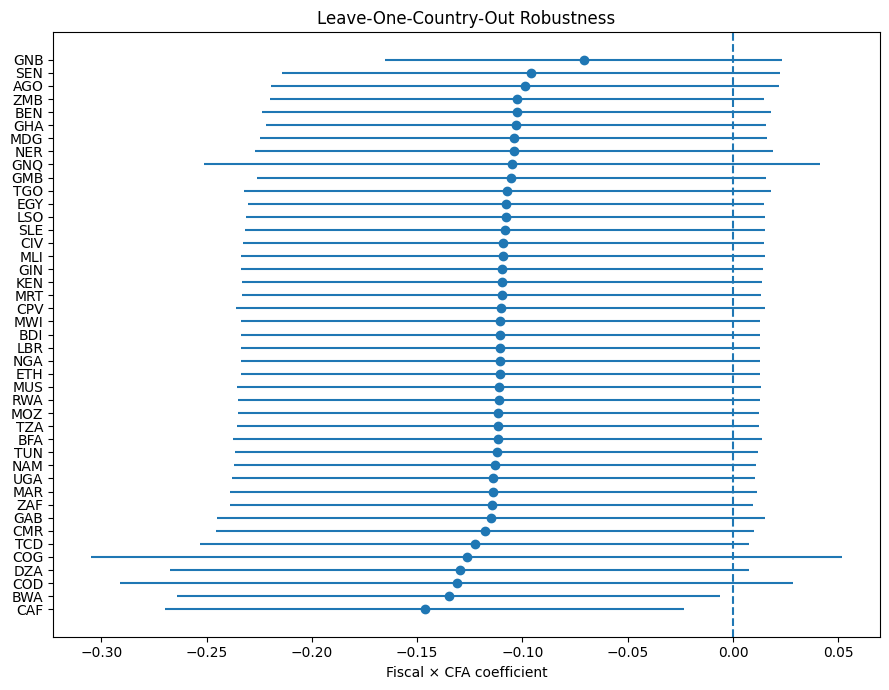


(C) COMPARISON COUNTRIES

Controls retained: ['DZA', 'BWA', 'BDI', 'EGY', 'ETH', 'GHA', 'LSO', 'MDG', 'MWI', 'MRT', 'MUS', 'MAR', 'RWA', 'ZAF', 'TUN', 'GMB', 'CPV']

Controls excluded: ['AGO', 'COD', 'GIN', 'KEN', 'LBR', 'MOZ', 'NAM', 'NGA', 'SLE', 'TZA', 'UGA', 'ZMB']

(D) CLEANER 1994 EVENT STUDY
Pretrend p-value: 0.42989327899291985


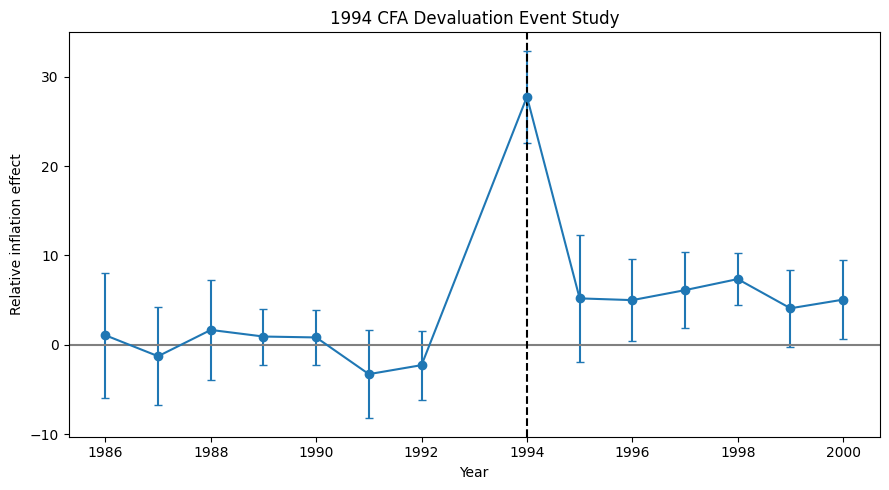


(E) PLACEBO TESTS
 Placebo year  Mean post effect  Pretrend p   N
         1989         -2.672772    0.169319 225
         1990         -2.092638    0.516542 230

ALL ROBUSTNESS CHECKS COMPLETED
Files saved in: /content/Q3_CFA_outputs/robustness


In [12]:

# ============================================================
# Q3 — SECTION 8: ROBUSTNESS ANALYSIS
# Run after the main Q3 analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from linearmodels.panel import PanelOLS

fv = FISCAL_VAR

ROBUST_DIR = Path("Q3_CFA_outputs/robustness")
ROBUST_DIR.mkdir(parents=True, exist_ok=True)

BASE = ["fisc_l1", "fisc_x_cfa"] + CONTROLS


# ============================================================
# 8A. OUTLIER ROBUSTNESS
# ============================================================

def clean_versions(P, fv, p=(0.01, 0.99)):

    A = P.copy(deep=True)
    B = P.copy(deep=True)

    for c in [fv, "gdp_g", "oil_rents", "m2_g"]:
        if c in B.columns:
            lo, hi = B[c].quantile(p)
            B[c] = B[c].clip(lo, hi)

    B = add_fiscal(B, fv)

    C = B.copy(deep=True)

    bad = (
        (C["infl"] > 50) |
        (C["infl"] < -10) |
        (C["gdp_g"].abs() > 15)
    ).fillna(False)

    print("Extreme country-years:", int(bad.sum()))

    C.loc[bad, ["y", fv, "gdp_g",
                "trade", "oil_rents", "m2_g"]] = np.nan

    C["y_l1"] = (
        C.groupby(level=0)["y"].shift(1)
    )

    C = add_fiscal(C, fv)

    return {
        "A Original": A,
        "B Winsorized": B,
        "C Trimmed": C
    }


# ============================================================
# 8B. COEFFICIENT STABILITY
# ============================================================

def stability_table(versions):

    rows = []

    for name, d in versions.items():

        row = {"Version": name}

        for model_name, dk in [
            ("FE", False),
            ("Driscoll-Kraay", True)
        ]:
            try:
                r, x = fit_panel(
                    d,
                    ["y_l1"] + BASE,
                    dk=dk
                )

                row[f"{model_name} fiscal"] = cell(
                    r, "fisc_l1"
                )

                row[f"{model_name} interaction"] = cell(
                    r, "fisc_x_cfa"
                )

                row[f"{model_name} N"] = r.nobs

            except Exception as e:
                row[f"{model_name} error"] = str(e)

        try:
            r, x = anderson_hsiao(
                d,
                BASE,
                drop_years=range(1994, 1998)
            )

            row["AH interaction"] = cell(
                r, "d_fisc_x_cfa"
            )

            row["AH persistence"] = cell(
                r, "dy_l1"
            )

        except Exception as e:
            row["AH error"] = str(e)

        rows.append(row)

    result = pd.DataFrame(rows).set_index("Version")

    result.to_csv(
        ROBUST_DIR / "stability.csv"
    )

    return result


# ============================================================
# 8C. LEAVE-ONE-COUNTRY-OUT
# ============================================================

def leave_one_out(d):

    rows = []

    countries = sorted(
        d.index.get_level_values(0).unique()
    )

    for country in countries:

        dd = d[
            d.index.get_level_values(0) != country
        ]

        try:
            r, x = fit_panel(
                dd,
                ["y_l1"] + BASE
            )

            rows.append({
                "Country excluded": country,
                "Coefficient": r.params["fisc_x_cfa"],
                "SE": r.std_errors["fisc_x_cfa"],
                "p-value": r.pvalues["fisc_x_cfa"]
            })

        except Exception as e:
            print("Failed:", country, e)

    result = pd.DataFrame(rows)

    if result.empty:
        raise ValueError("No successful LOO regressions")

    result = result.sort_values("Coefficient")

    print("\nCoefficient range:")
    print(
        result["Coefficient"].min(),
        result["Coefficient"].max()
    )

    print("\nSignificant at 10%:")
    print(
        (result["p-value"] < 0.10).sum(),
        "of", len(result)
    )

    result.to_csv(
        ROBUST_DIR / "leave_one_out.csv",
        index=False
    )

    plt.figure(figsize=(9, 7))

    plt.errorbar(
        result["Coefficient"],
        result["Country excluded"],
        xerr=1.96 * result["SE"],
        fmt="o"
    )

    plt.axvline(0, linestyle="--")

    plt.title("Leave-One-Country-Out Robustness")
    plt.xlabel("Fiscal × CFA coefficient")
    plt.tight_layout()

    plt.savefig(
        ROBUST_DIR / "leave_one_out.png",
        dpi=200
    )

    plt.show()

    return result


# ============================================================
# 8D. SCREEN COMPARISON COUNTRIES
# ============================================================

def matched_controls(
    P,
    max_pre_infl=25,
    max_any_infl=100,
    window=(1990, 1993)
):

    inf = P["infl"].unstack(level=1)

    pre = inf.loc[
        :, window[0]:window[1]
    ].mean(axis=1)

    # Only pre-treatment information
    mx = inf.loc[
        :, 1985:1993
    ].max(axis=1)

    non = [
        c for c in NON_CFA
        if c in inf.index
    ]

    keep = [
        c for c in non
        if pd.notna(pre[c])
        and pd.notna(mx[c])
        and pre[c] < max_pre_infl
        and mx[c] < max_any_infl
    ]

    drop = [
        c for c in non
        if c not in keep
    ]

    print("\nControls retained:", keep)
    print("\nControls excluded:", drop)

    return keep, drop


# ============================================================
# 8E. CLEANER 1994 EVENT STUDY
# ============================================================

def cleaner_event_study(
    P,
    controls,
    year0=1994,
    pre=8,
    post=6
):

    treated = [
        c for c in CFA if c != "GNB"
    ]

    z = P.reset_index()

    z = z[
        z.country.isin(treated + controls) &
        z.year.between(year0-pre, year0+post)
    ].copy()

    z["treated"] = z.country.isin(
        treated
    ).astype(int)

    z = z[
        ["country", "year", "y", "treated"]
    ].dropna()

    ks = [
        k for k in range(-pre, post+1)
        if k != -1
    ]

    for k in ks:
        z[f"event_{k}"] = (
            z.treated *
            (z.year == year0+k)
        ).astype(float)

    z = z.set_index(
        ["country", "year"]
    ).sort_index()

    cols = [f"event_{k}" for k in ks]

    model = PanelOLS(
        z["y"],
        z[cols],
        entity_effects=True,
        time_effects=True,
        drop_absorbed=True
    )

    res = model.fit(
        cov_type="clustered",
        cluster_entity=True
    )

    est = pd.DataFrame({
        "k": ks,
        "year": [year0+k for k in ks],
        "coef": [
            res.params.get(f"event_{k}", np.nan)
            for k in ks
        ],
        "se": [
            res.std_errors.get(f"event_{k}", np.nan)
            for k in ks
        ]
    })

    est["lower95"] = est.coef - 1.96*est.se
    est["upper95"] = est.coef + 1.96*est.se

    pre_names = [
        f"event_{k}" for k in ks
        if k < -1 and f"event_{k}" in res.params.index
    ]

    R = np.zeros(
        (len(pre_names), len(res.params))
    )

    for j, name in enumerate(pre_names):
        R[j, res.params.index.get_loc(name)] = 1

    pretrend_p = (
        float(res.wald_test(R).pval)
        if len(pre_names) else np.nan
    )

    return est, pretrend_p, res


# ============================================================
# 8F. PLACEBO TESTS
# ============================================================

def placebo_tests(P, controls):

    # No post-1993 observations in placebo estimation
    pre_data = P[
        P.index.get_level_values("year") <= 1993
    ]

    rows = []

    for year in [1989, 1990]:

        try:
            est, p, res = cleaner_event_study(
                pre_data,
                controls,
                year0=year,
                pre=4,
                post=min(3, 1993-year)
            )

            rows.append({
                "Placebo year": year,
                "Mean post effect": est.loc[
                    est.k >= 0, "coef"
                ].mean(),
                "Pretrend p": p,
                "N": res.nobs
            })

        except Exception as e:
            print("Placebo failed:", year, e)

    result = pd.DataFrame(rows)

    result.to_csv(
        ROBUST_DIR / "placebo.csv",
        index=False
    )

    return result


# ============================================================
# 8G. RUN ALL ROBUSTNESS TESTS
# ============================================================

print("\n========== Q3 ROBUSTNESS ==========")

# A. Outliers and cleaning
versions = clean_versions(P, fv)

# B. Coefficient stability
print("\n(A) STABILITY ACROSS DATA CLEANING")

stability = stability_table(versions)
print(stability.to_string())

# C. Leave-one-country-out
print("\n(B) LEAVE-ONE-COUNTRY-OUT")

loo = leave_one_out(P)

# D. Select comparison countries
print("\n(C) COMPARISON COUNTRIES")

keep, drop = matched_controls(P)

# E. Cleaner event study
print("\n(D) CLEANER 1994 EVENT STUDY")

est, pretrend_p, event_res = cleaner_event_study(
    P, keep
)

print("Pretrend p-value:", pretrend_p)

est.to_csv(
    ROBUST_DIR / "cleaner_event_study.csv",
    index=False
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    est.year,
    est.coef,
    yerr=1.96*est.se,
    fmt="o-",
    capsize=3
)

plt.axhline(0, color="gray")
plt.axvline(1994, linestyle="--", color="black")

plt.title("1994 CFA Devaluation Event Study")
plt.xlabel("Year")
plt.ylabel("Relative inflation effect")
plt.tight_layout()

plt.savefig(
    ROBUST_DIR / "cleaner_event_study.png",
    dpi=200
)

plt.show()

# F. Placebo tests
print("\n(E) PLACEBO TESTS")

placebo = placebo_tests(P, keep)
print(placebo.to_string(index=False))

print("\nALL ROBUSTNESS CHECKS COMPLETED")
print("Files saved in:", ROBUST_DIR.resolve())
